## Data Understanding


In [1]:
import pandas as pd
import matplotlib as plt

In [2]:
df=pd.read_csv('supply_chain_dataset1.csv',parse_dates=['Date'])

In [3]:
df.sample(5)

,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
62546,2024-05-11,SKU_35,WH_2,SUP_4,South,29,736,12,356,428,13.09,21.71,0,0,32.70
36140,2024-01-06,SKU_20,WH_5,SUP_5,West,32,711,2,246,0,10.07,18.03,1,0,32.90
39366,2024-11-07,SKU_22,WH_3,SUP_9,East,8,247,4,211,0,18.38,32.58,0,0,0.36
80596,2024-10-23,SKU_45,WH_1,SUP_7,North,4,508,8,256,0,7.29,10.79,0,0,1.57
69340,2024-12-21,SKU_38,WH_5,SUP_5,West,20,406,13,273,0,19.30,34.25,0,0,16.03


In [5]:
df.shape

(91250, 15)

In [6]:
counts = df.groupby(["SKU_ID", "Warehouse_ID"]).size()
print(counts.head(10))     # first 10 pairs, each should be 365
print(len(counts))         # number of pairs, should be 250
print(counts.unique())     # should print [365]

SKU_ID  Warehouse_ID
SKU_1   WH_1            365
        WH_2            365
        WH_3            365
        WH_4            365
        WH_5            365
SKU_10  WH_1            365
        WH_2            365
        WH_3            365
        WH_4            365
        WH_5            365
dtype: int64
250
[365]


In [ ]:
print(df.groupby("SKU_ID").size().head())   # each should be 1825 (5 × 365), split around each each warehouse

SKU_ID
SKU_1     1825
SKU_10    1825
SKU_11    1825
SKU_12    1825
SKU_13    1825
dtype: int64


In [10]:
df.isnull().sum()

Date                       0
SKU_ID                     0
Warehouse_ID               0
Supplier_ID                0
Region                     0
Units_Sold                 0
Inventory_Level            0
Supplier_Lead_Time_Days    0
Reorder_Point              0
Order_Quantity             0
Unit_Cost                  0
Unit_Price                 0
Promotion_Flag             0
Stockout_Flag              0
Demand_Forecast            0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
fixed = ["Supplier_ID", "Supplier_Lead_Time_Days", "Reorder_Point", "Unit_Cost", "Unit_Price", "Region"]
print(df.groupby(["SKU_ID", "Warehouse_ID"])[fixed].nunique().max())

Supplier_ID                1
Supplier_Lead_Time_Days    1
Reorder_Point              1
Unit_Cost                  1
Unit_Price                 1
Region                     4
dtype: int64


In [13]:
print(df.groupby("Supplier_ID")["Supplier_Lead_Time_Days"].nunique())

Supplier_ID
SUP_1     12
SUP_10    10
SUP_2     11
SUP_3     12
SUP_4     10
SUP_5     11
SUP_6     11
SUP_7     11
SUP_8     13
SUP_9     12
Name: Supplier_Lead_Time_Days, dtype: int64


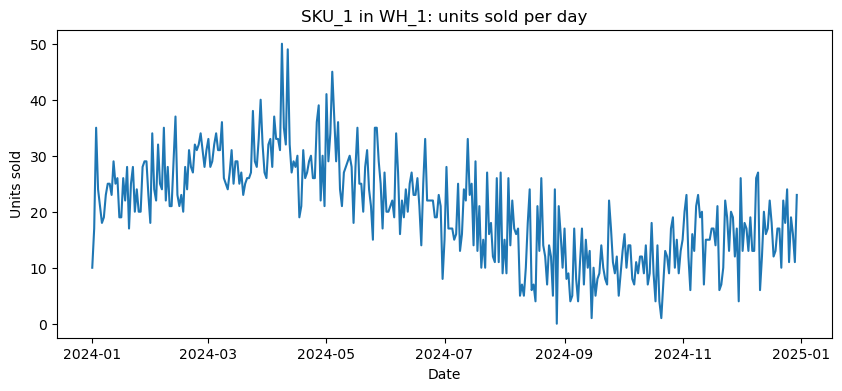

In [14]:
import matplotlib.pyplot as plt

one = df[(df.SKU_ID == "SKU_1") & (df.Warehouse_ID == "WH_1")]

plt.figure(figsize=(10, 4))
plt.plot(one["Date"], one["Units_Sold"])
plt.title("SKU_1 in WH_1: units sold per day")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.show()

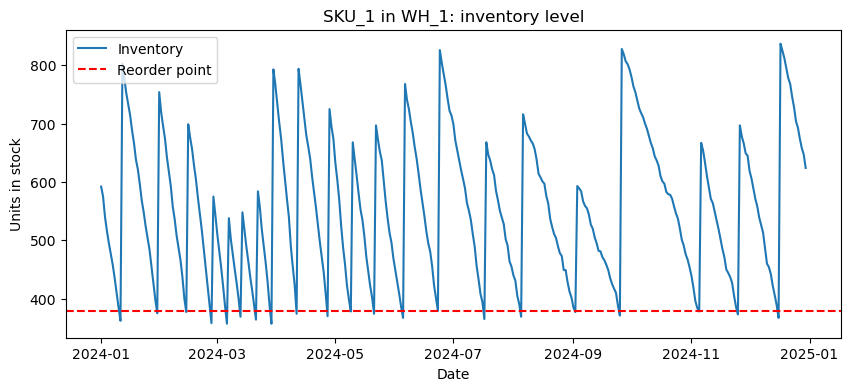

In [15]:
plt.figure(figsize=(10, 4))
plt.plot(one["Date"], one["Inventory_Level"], label="Inventory")
plt.axhline(one["Reorder_Point"].iloc[0], color="red", linestyle="--", label="Reorder point")
plt.title("SKU_1 in WH_1: inventory level")
plt.xlabel("Date")
plt.ylabel("Units in stock")
plt.legend()
plt.show()

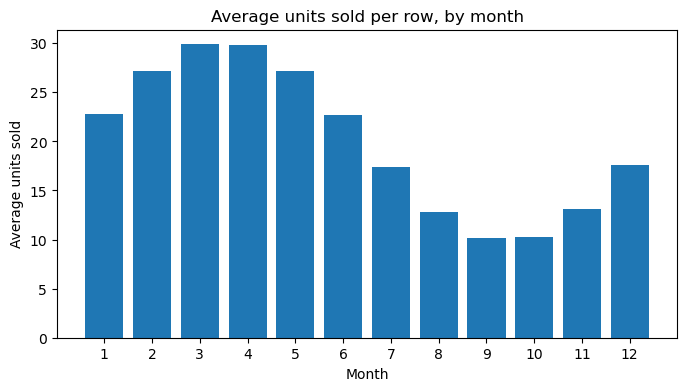

In [16]:
monthly = df.groupby(df["Date"].dt.month)["Units_Sold"].mean()

plt.figure(figsize=(8, 4))
plt.bar(monthly.index, monthly.values)
plt.title("Average units sold per row, by month")
plt.xlabel("Month")
plt.ylabel("Average units sold")
plt.xticks(range(1, 13))
plt.show()

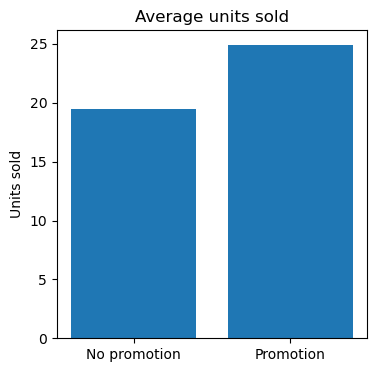

In [17]:
promo = df.groupby("Promotion_Flag")["Units_Sold"].mean()

plt.figure(figsize=(4, 4))
plt.bar(["No promotion", "Promotion"], promo.values)
plt.title("Average units sold")
plt.ylabel("Units sold")
plt.show()

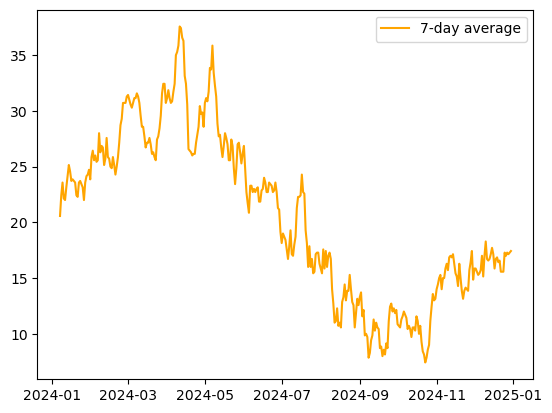

In [18]:
plt.plot(one["Date"], one["Units_Sold"].rolling(7).mean(), color="orange", label="7-day average")
plt.legend()